# Phase 7 — Is the second half of a diagonal actually visible?

### The question

Both models miss most diagonals, and in ~80% of misses they get **one half** right (UPLEFT → UP or LEFT). Our guess: in a corridor, pressing UPLEFT moves Pac-Man exactly like UP, so the frames simply don't contain the "LEFT" part.

We can test that directly. Pac-Man is yellow in the original frames, so we can find him and measure **which way he actually moved** after each button press. Then two predictions follow if the guess is right:

1. **For diagonal presses, Pac-Man usually moves along only one axis.** The other half of the press has no visible effect.
2. **The model's "half" matches the axis he really moved on.** It's reading the screen correctly, and when he moves on **both** axes (turning a corner, so the full diagonal is visible), the model gets the exact diagonal **more often**.

If those hold, the diagonal ceiling is a property of the data, not the model. That's a big claim for any IDM, and worth checking carefully.

**Runs on your laptop** (no GPU needed). It re-reads the 3 test sessions' original color frames, which takes about 5–15 minutes.

**You need:** `results/test_preds.npz` (downloaded from Drive), plus the Phase 1 raw data and Phase 2 processed data still on your laptop.

## 1. Setup: load predictions and check they line up

In [1]:
import os, sys, io, json, tarfile
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

ROOT = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(ROOT, "README.md")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)
from src.labels import CLASS_NAMES as NAMES

PROC = os.path.join(ROOT, "data", "processed")
meta = json.load(open(os.path.join(PROC, "meta.json")))
sp = np.load(os.path.join(PROC, "splits.npz"))
MID = meta["mid"]

pred_path = next((p for p in [os.path.join(ROOT, "results", "test_preds.npz"), os.path.join(ROOT, "test_preds.npz"),
                              os.path.join(PROC, "test_preds.npz")] if os.path.exists(p)), None)
assert pred_path, "Put test_preds.npz in a results/ folder in your repo"
P = np.load(pred_path)
labels, base_pred, fact_pred = P["labels"], P["baseline"], P["factorized"]
starts = sp["test_starts"]

# the predictions must be in the same order as the saved test clips
assert len(labels) == len(starts) and np.array_equal(labels, sp["test_labels"]), "test_preds.npz doesn't match splits.npz"
print(f"{len(labels):,} test clips, predictions line up with splits.npz")
print("test sessions:", meta["sessions"]["test"])

13,258 test clips, predictions line up with splits.npz
test sessions: ['273_RZ_3279899_Mar-22-13-39-02', '61_RZ_2737165_Aug-14-14-09-12', '64_RZ_2809807_Aug-15-10-11-14']


## 2. Map each test clip back to its session and original frame

`frames.npy` is all sessions glued end to end, in the order Phase 2 processed them (sorted by name). To find the original PNG for a clip, we rebuild where each session starts. Phase 2 kept 100% of labeled frames, so a session's length = its number of labeled rows.

In [2]:
candidates = [os.path.join(ROOT, "data", "raw", "ms_pacman"), os.path.join(ROOT, "notebooks", "data", "raw", "ms_pacman")]
RAW_DIR = next((p for p in candidates if os.path.isdir(p)), None)
assert RAW_DIR, f"Raw data not found in {candidates}"

trials = []
for root, _, fnames in os.walk(RAW_DIR):
    for fn in fnames:
        if fn.endswith(".tar.bz2") and os.path.exists(os.path.join(root, fn[:-8] + ".txt")):
            trials.append((root, fn[:-8]))
trials.sort(key=lambda t: t[1])                       # same order as Phase 2

def read_rows(root, stem):
    rows = []
    with open(os.path.join(root, stem + ".txt")) as f:
        f.readline()
        for line in f:
            p = line.strip().split(",")
            if len(p) > 5:
                try:
                    rows.append((p[0], int(p[5])))
                except ValueError:
                    pass
    return rows

rows = {stem: read_rows(root, stem) for root, stem in trials}
sizes = [len(rows[s]) for _, s in trials]
offsets = np.concatenate([[0], np.cumsum(sizes)])
n_frames = np.load(os.path.join(PROC, "frames.npy"), mmap_mode="r").shape[0]
assert offsets[-1] == n_frames, f"session lengths add to {offsets[-1]:,} but frames.npy has {n_frames:,}"

mids = starts + MID                                    # global index of each clip's labeled frame
trial_idx = np.searchsorted(offsets, mids, side="right") - 1
local_mid = mids - offsets[trial_idx]
print(f"OK: {len(trials)} sessions, {n_frames:,} frames, mapping rebuilt")
print("clips per test session:", Counter(trials[t][1] for t in trial_idx))

OK: 22 sessions, 388,602 frames, mapping rebuilt
clips per test session: Counter({'273_RZ_3279899_Mar-22-13-39-02': 4440, '64_RZ_2809807_Aug-15-10-11-14': 4421, '61_RZ_2737165_Aug-14-14-09-12': 4397})


## 3. Find Pac-Man

In the Atari game, Ms. Pac-Man is drawn in one exact yellow, RGB (210, 164, 74). The ghosts use other colors. We find every pixel of that color in the play area (above the score bar) and take their average position.

**Check the pictures below.** The red cross should sit on Pac-Man in every frame. If it doesn't, or the detection rate is low, tell me what you see.

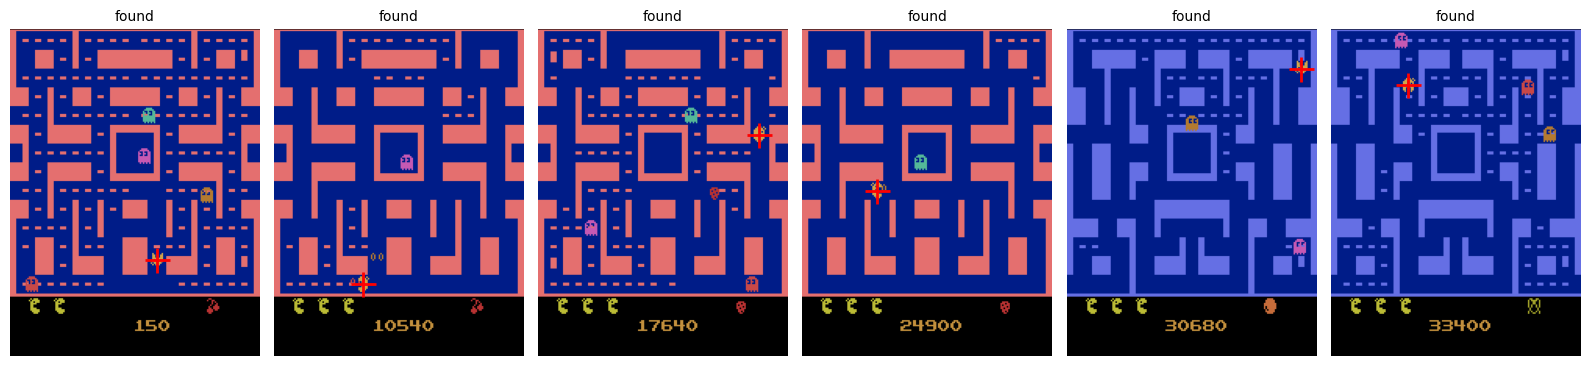

In [3]:
PACMAN_RGB = np.array([210, 164, 74])
PLAY_ROWS = 172          # rows below this are the score / lives bar

def find_pacman(rgb, tol=10):
    area = rgb[:PLAY_ROWS].astype(int)
    mask = (np.abs(area - PACMAN_RGB) <= tol).all(axis=2)
    ys, xs = np.nonzero(mask)
    if len(xs) < 3:
        return None
    return float(xs.mean()), float(ys.mean())

def read_frames(root, stem, wanted_ids):
    """Stream a session's .tar.bz2 and return {frame_id: RGB array} for the ids we want."""
    out = {}
    with tarfile.open(os.path.join(root, stem + ".tar.bz2"), "r:bz2") as tar:
        for m in tar:
            name = os.path.basename(m.name)
            if name.endswith(".png") and name[:-4] in wanted_ids:
                out[name[:-4]] = np.asarray(Image.open(io.BytesIO(tar.extractfile(m).read())).convert("RGB"))
    return out

# look at 6 frames from the first test session
t0 = trial_idx[0]
root0, stem0 = trials[t0]
sample_local = np.linspace(500, sizes[t0] - 500, 6).astype(int)
imgs = read_frames(root0, stem0, {rows[stem0][i][0] for i in sample_local})

fig, axes = plt.subplots(1, 6, figsize=(16, 4))
for ax, i in zip(axes, sample_local):
    rgb = imgs[rows[stem0][i][0]]
    ax.imshow(rgb); ax.axis("off")
    pos = find_pacman(rgb)
    if pos:
        ax.plot(*pos, "r+", ms=18, mew=2)
    ax.set_title("found" if pos else "NOT FOUND", color="black" if pos else "red", fontsize=10)
plt.tight_layout(); plt.show()

If Pac-Man isn't found, this lists the most common colors in the play area so we can pick the right one:

In [ ]:
rgb = imgs[rows[stem0][sample_local[2]][0]][:PLAY_ROWS].reshape(-1, 3)
common = Counter(tuple(int(v) for v in px) for px in rgb).most_common(12)
for color, n in common:
    print(color, n, "pixels")

## 4. Track Pac-Man in every test clip

For each test clip we locate him at the **labeled frame** and **K frames later**, then compute how far he moved: `dx` (+ = right) and `dy` (+ = **down**, because image rows count downward).

K = 8 raw frames (two of the model's sampled frames). Pac-Man moves roughly 1 pixel per frame, so that's enough to see a direction. Too large a K and he may have already turned again.

In [5]:
K = 8
need = {}                                   # session -> set of frame ids
for t, m in zip(trial_idx, local_mid):
    stem = trials[t][1]
    for i in (m, m + K):
        if i < sizes[t]:
            need.setdefault(stem, set()).add(rows[stem][i][0])

positions = {}                              # (session, frame_id) -> (x, y) or None
for root, stem in trials:
    if stem not in need:
        continue
    with tarfile.open(os.path.join(root, stem + ".tar.bz2"), "r:bz2") as tar:
        for m in tqdm(tar, desc=stem[:20], total=sizes[trials.index((root, stem))]):
            name = os.path.basename(m.name)
            if name.endswith(".png") and name[:-4] in need[stem]:
                rgb = np.asarray(Image.open(io.BytesIO(tar.extractfile(m).read())).convert("RGB"))
                positions[(stem, name[:-4])] = find_pacman(rgb)

found = sum(v is not None for v in positions.values())
print(f"located Pac-Man in {found:,} of {len(positions):,} frames ({100 * found / len(positions):.1f}%)")

273_RZ_3279899_Mar-2:   0%|          | 0/17820 [00:00<?, ?it/s]

61_RZ_2737165_Aug-14:   0%|          | 0/17646 [00:00<?, ?it/s]

64_RZ_2809807_Aug-15:   0%|          | 0/17741 [00:00<?, ?it/s]

located Pac-Man in 12,863 of 13,264 frames (97.0%)


**Detection rate check:** it should be well above 90%. Pac-Man disappears briefly when he dies and between levels, so 100% isn't expected.

## 5. Classify how he moved after each press

In [6]:
T = 2.0          # pixels: smaller movements count as "didn't move on that axis"
WRAP = 40.0      # bigger jumps = going through the side tunnel (teleport), ignore

dx = np.full(len(labels), np.nan); dy = np.full(len(labels), np.nan)
for k, (t, m) in enumerate(zip(trial_idx, local_mid)):
    stem = trials[t][1]
    if m + K >= sizes[t]:
        continue
    a = positions.get((stem, rows[stem][m][0])); b = positions.get((stem, rows[stem][m + K][0]))
    if a and b and abs(b[0] - a[0]) < WRAP and abs(b[1] - a[1]) < WRAP:
        dx[k], dy[k] = b[0] - a[0], b[1] - a[1]

ok = ~np.isnan(dx)
moved_h = ok & (np.abs(dx) >= T)
moved_v = ok & (np.abs(dy) >= T)
motion = np.where(~ok, "unknown", np.where(moved_h & moved_v, "both",
                  np.where(moved_h, "h only", np.where(moved_v, "v only", "still"))))
print(f"usable clips: {ok.sum():,} of {len(labels):,}")
print(Counter(motion))

usable clips: 12,688 of 13,258
Counter({'h only': 5260, 'v only': 4784, 'still': 1877, 'both': 767, 'unknown': 570})


## 6. Does the tracker agree with the labels on simple moves?

Before trusting it on diagonals, check the easy cases. For clips labeled UP, Pac-Man should mostly be moving up afterwards, and so on. This validates the tracker, and the sign convention (dy < 0 = up).

It won't be 100%: a press can take a few frames to take effect (he keeps going until he reaches an opening), so some UP clips show him still moving sideways.

In [7]:
def observed_dir(k):
    if motion[k] in ("unknown", "still"):
        return motion[k]
    if abs(dx[k]) >= abs(dy[k]):
        return "RIGHT" if dx[k] > 0 else "LEFT"
    return "DOWN" if dy[k] > 0 else "UP"

obs = np.array([observed_dir(k) for k in range(len(labels))])
print(f"{'label':8s} {'n':>6s}   observed motion over the next {K} frames")
for name in ["UP", "DOWN", "LEFT", "RIGHT", "NOOP"]:
    m = (labels == NAMES.index(name)) & ok
    c = Counter(obs[m])
    print(f"{name:8s} {m.sum():6,d}   " + "  ".join(f"{d}:{100 * c[d] / max(m.sum(), 1):.0f}%"
                                              for d in ["UP", "DOWN", "LEFT", "RIGHT", "still"]))

label         n   observed motion over the next 8 frames
UP        2,525   UP:90%  DOWN:0%  LEFT:2%  RIGHT:2%  still:6%
DOWN      2,463   UP:0%  DOWN:89%  LEFT:2%  RIGHT:2%  still:7%
LEFT      3,589   UP:3%  DOWN:4%  LEFT:76%  RIGHT:0%  still:17%
RIGHT     2,899   UP:3%  DOWN:2%  LEFT:1%  RIGHT:85%  still:10%
NOOP        675   UP:1%  DOWN:2%  LEFT:2%  RIGHT:1%  still:94%


**What to look for:** the biggest number in each row should be the row's own direction (UP row → mostly UP). If instead the rows look shuffled, the tracker is wrong, so stop and tell me.

## 7. The diagonal test

**Prediction 1:** for diagonal presses, Pac-Man mostly moves on **one** axis.

In [8]:
DIAGS = [NAMES.index(n) for n in ["UPLEFT", "UPRIGHT", "DOWNLEFT", "DOWNRIGHT"]]
is_diag = np.isin(labels, DIAGS) & ok
print(f"{is_diag.sum()} diagonal test clips with usable tracking\n")
c = Counter(motion[is_diag])
for k in ["v only", "h only", "both", "still"]:
    print(f"  {k:7s} {c[k]:4d}  {100 * c[k] / is_diag.sum():5.1f}%")

537 diagonal test clips with usable tracking

  v only   210   39.1%
  h only   156   29.1%
  both     164   30.5%
  still      7    1.3%


**Prediction 2:** when he moves on only one axis, the model's guess matches **that** axis. When he moves on both, it gets the exact diagonal more often.

For a diagonal press, each model's prediction is one of:
- **exact:** the full diagonal
- **seen half:** the cardinal direction he actually moved along (e.g. UPLEFT, moved only up → predicted UP)
- **unseen half:** the other cardinal (UPLEFT, moved only up → predicted LEFT)
- **other:** anything else

In [9]:
def breakdown(pred, mask):
    res = Counter()
    for k in np.flatnonzero(mask):
        d, p = labels[k], pred[k]
        h_card, v_card = 3 * 1 + d % 3, 3 * (d // 3) + 1      # the two cardinal halves of diagonal d
        if p == d:
            res["exact"] += 1
        elif motion[k] == "v only":
            res["seen half" if p == v_card else "unseen half" if p == h_card else "other"] += 1
        elif motion[k] == "h only":
            res["seen half" if p == h_card else "unseen half" if p == v_card else "other"] += 1
        else:
            res["half (no single axis)" if p in (h_card, v_card) else "other"] += 1
    n = mask.sum()
    return n, {k: 100 * v / max(n, 1) for k, v in res.items()}

summary = {}
for group, gmask in [("moved on ONE axis", is_diag & np.isin(motion, ["v only", "h only"])),
                     ("moved on BOTH axes", is_diag & (motion == "both"))]:
    print(f"\n{group}")
    for mname, pred in [("baseline", base_pred), ("factorized", fact_pred)]:
        n, b = breakdown(pred, gmask)
        summary[(group, mname)] = b
        print(f"  {mname:10s} n={n:3d}  " + "  ".join(f"{k}: {v:.0f}%" for k, v in sorted(b.items(), key=lambda kv: -kv[1])))


moved on ONE axis
  baseline   n=366  seen half: 70%  exact: 15%  unseen half: 14%  other: 1%
  factorized n=366  seen half: 74%  exact: 13%  unseen half: 11%  other: 1%

moved on BOTH axes
  baseline   n=164  half (no single axis): 74%  exact: 26%
  factorized n=164  half (no single axis): 77%  exact: 23%


## 8. The article figure

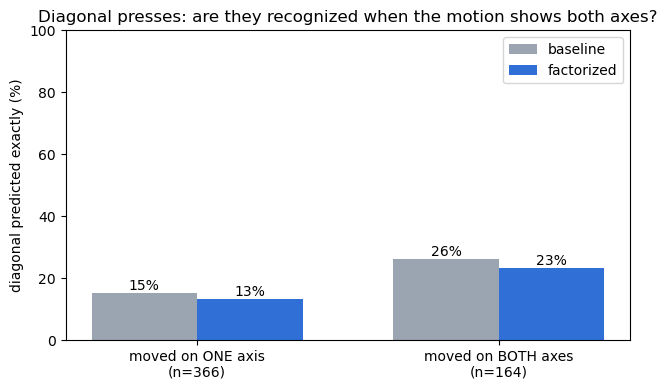

saved figures/diagonal_visibility.png and results/motion_test.npz


In [10]:
groups = ["moved on ONE axis", "moved on BOTH axes"]
x = np.arange(2)
fig, ax = plt.subplots(figsize=(6.5, 4))
for j, (mname, color) in enumerate([("baseline", "#9aa5b1"), ("factorized", "#2f6fd6")]):
    vals = [summary[(g, mname)].get("exact", 0) for g in groups]
    bars = ax.bar(x + (j - 0.5) * 0.35, vals, 0.35, label=mname, color=color)
    ax.bar_label(bars, fmt="%.0f%%")
ns = [(is_diag & np.isin(motion, ["v only", "h only"])).sum(), (is_diag & (motion == "both")).sum()]
ax.set_xticks(x); ax.set_xticklabels([f"{g}\n(n={n})" for g, n in zip(groups, ns)])
ax.set_ylabel("diagonal predicted exactly (%)"); ax.set_ylim(0, 100); ax.legend()
ax.set_title("Diagonal presses: are they recognized when the motion shows both axes?")
plt.tight_layout()
os.makedirs(os.path.join(ROOT, "figures"), exist_ok=True)
plt.savefig(os.path.join(ROOT, "figures", "diagonal_visibility.png"), dpi=150); plt.show()

np.savez(os.path.join(ROOT, "results", "motion_test.npz"), dx=dx, dy=dy, motion=motion, labels=labels,
         baseline=base_pred, factorized=fact_pred, K=K, T=T)
print("saved figures/diagonal_visibility.png and results/motion_test.npz")

## How to read the result

**The hypothesis is supported if:**
1. Most diagonal presses show motion on only one axis (step 7, first table).
2. In those, "seen half" dominates "unseen half" by a lot.
3. "Exact" is clearly higher in the "moved on BOTH axes" group.

**It's weakened if** "seen half" and "unseen half" are about equal (the model would be guessing, not reading motion), or if exact accuracy is the same in both groups.

**Caveats to mention in the article:**
- The "both axes" group is small, so its percentages are noisy.
- K and T are choices. Try K = 4 and K = 12 and see whether the conclusion holds; if it does, say so.
- Motion is measured right after the press, but a press can take effect late (he waits for an opening), so some "one axis" clips may be presses that simply hadn't kicked in yet.

Send me the outputs of steps 3 (the pictures), 4, 6 and 7.

In [11]:
both = (motion == "both")
print("Share of clips where Pac-Man moved on BOTH axes, by label:")
for i, name in enumerate(NAMES):
    m = (labels == i) & ok
    print(f"  {name:10s} {100 * both[m].mean():5.1f}%   ({both[m].sum()} of {m.sum()})")
d = np.isin(labels, DIAGS)
print(f"\nOf all {both.sum()} clips with both-axis motion, only {100 * d[both].mean():.0f}% were diagonal presses.")

Share of clips where Pac-Man moved on BOTH axes, by label:
  UPLEFT      29.8%   (39 of 131)
  UP           4.1%   (103 of 2525)
  UPRIGHT     28.8%   (45 of 156)
  LEFT         5.9%   (213 of 3589)
  NOOP         0.6%   (4 of 675)
  RIGHT        6.0%   (174 of 2899)
  DOWNLEFT    26.7%   (32 of 120)
  DOWN         4.4%   (109 of 2463)
  DOWNRIGHT   36.9%   (48 of 130)

Of all 767 clips with both-axis motion, only 21% were diagonal presses.
